<a href="https://colab.research.google.com/github/kumarsaurabh1817/Final-Computer-Vision-Training/blob/main/week5_vlms/day1_vlm_architecture/Week5_Day1_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5 · Day 1 — How Vision-Language Models Work

**Goal:** open the box. A VLM is three parts glued together — a **vision encoder** that turns pixels into patch features, a **projector** that maps those features into the LLM's embedding space, and an **LLM** that reads the result as if it were extra words. After today you can explain where every visual token comes from and what it costs.

| Topic | What you will build / measure |
|---|---|
| Architecture | Parameter count per component (vision / projector / LLM) for Qwen3-VL and a LLaVA-style model |
| Visual tokens | How many tokens an image becomes, as a function of resolution; the chat template with image placeholders |
| Projector | A forward hook that shows the projector's output shape = (visual tokens × LLM hidden size) |
| First runs | Captioning, VQA, counting, reading text, comparing two images — with latency and tokens/s |
| Cost of pixels | Visual tokens vs latency on the same image |
| Hallucination probe | POPE-style yes/no object questions: accuracy and "yes" bias |
| Visual instruction tuning | What LLaVA-style training data looks like, and which tokens the loss is computed on |

**Data:** [Flickr8k on Kaggle](https://www.kaggle.com/datasets/adityajn105/flickr8k) — 8,091 photos, 5 human captions each (~1 GB).

**Models:** [`Qwen/Qwen3-VL-4B-Instruct`](https://huggingface.co/Qwen/Qwen3-VL-4B-Instruct) (Apache 2.0) and [`llava-hf/llava-onevision-qwen2-0.5b-ov-hf`](https://huggingface.co/llava-hf/llava-onevision-qwen2-0.5b-ov-hf) (LLaVA architecture, small enough to load next to it).

> Runtime: **T4 GPU**, ~15–20 min with `FULL_RUN=True`. Kaggle credentials: see section 2.

## 0 · Install dependencies

In [1]:
import subprocess
import sys


def pip_install(*packages: str) -> None:
    """Install packages into the running interpreter (works in Colab and plain Python)."""
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])


pip_install("transformers>=4.57", "accelerate>=1.0", "kagglehub>=0.3")

## 1 · Imports, configuration, and output folder

In [2]:
import json
import os
import random
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # headless when run as a script

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw, ImageFont
from transformers import AutoModelForImageTextToText, AutoProcessor

IN_COLAB = "google.colab" in sys.modules
try:
    HERE = Path(__file__).resolve().parent
except NameError:  # running inside a notebook
    HERE = Path.cwd()

OUTPUT_DIR = Path("/content/week5_outputs/day1") if IN_COLAB else HERE.parent / "results" / "day1"
DATA_DIR = Path("/content/datasets") if IN_COLAB else HERE.parent / "data"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

FULL_RUN = True  # False = quick smoke test (fewer images and probes)
VLM_ID = "Qwen/Qwen3-VL-4B-Instruct"  # "Qwen/Qwen3-VL-2B-Instruct" is ~2x faster
LLAVA_ID = "llava-hf/llava-onevision-qwen2-0.5b-ov-hf"
RUN_LLAVA = True
N_POPE = 40 if FULL_RUN else 6  # images for the hallucination probe (2 questions each)
MAX_SIDE = 896  # longest image side fed to the VLM; more pixels = more visual tokens
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | device={DEVICE} | FULL_RUN={FULL_RUN}")
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print("Outputs ->", OUTPUT_DIR)


def save_fig(fig, name: str) -> None:
    """Save a figure to OUTPUT_DIR and show it inline when in a notebook."""
    path = OUTPUT_DIR / name
    fig.savefig(path, dpi=120, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)
    print(f"saved -> {path}")

PyTorch 2.11.0+cu130 | device=cuda | FULL_RUN=True
Tesla T4 15.6 GB
Outputs -> /content/week5_outputs/day1


## 2 · Helper code: Kaggle download, Flickr8k loader, VLM wrapper

**Kaggle credentials (once):** kaggle.com → *Settings → API → Create New Token*. In Colab open the **key icon (Secrets)** and add either `KAGGLE_API_TOKEN` (new-style token), or `KAGGLE_USERNAME` + `KAGGLE_KEY` (from `kaggle.json`), and switch on *Notebook access*.
No credentials? Download the zip from the Kaggle page, upload it to Colab, and unzip it into `/content/datasets/flickr8k/`.

In [3]:
# ---- data.py: helper code for this day (self-contained, no external project files) ----
def get_secret(name: str) -> str | None:
    """Environment variable first, then Colab secrets."""
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return None


USE_DRIVE = True  # Colab: look for datasets in Google Drive before downloading
DRIVE_DATASETS = Path("/content/drive/MyDrive/datasets")


def drive_datasets() -> Path | None:
    """Mount Google Drive (Colab only, asks for permission once) and return the datasets folder, or None."""
    if not (IN_COLAB and USE_DRIVE):
        return None
    if not Path("/content/drive/MyDrive").exists():
        from google.colab import drive
        drive.mount("/content/drive")
    return DRIVE_DATASETS if DRIVE_DATASETS.exists() else None


def kaggle_dataset(slug: str, local_name: str) -> Path:
    """
    Folder of a Kaggle dataset, found or downloaded once.

    1. DATA_DIR/<local_name>, if it is already there (unzipped earlier in this session, or by you).
    2. Google Drive: DRIVE_DATASETS/<local_name>.zip is unzipped to DATA_DIR (local disk is much faster than
       reading thousands of files from Drive); an unzipped DRIVE_DATASETS/<local_name>/ folder is used directly.
    3. kagglehub.dataset_download(slug). Public datasets usually need no login; otherwise it uses KAGGLE_API_TOKEN
       or KAGGLE_USERNAME + KAGGLE_KEY (env or Colab secrets) or ~/.kaggle/kaggle.json. kagglehub caches downloads.
    """
    manual = DATA_DIR / local_name
    if manual.exists() and any(manual.iterdir()):
        return manual
    drive_dir = drive_datasets()
    if drive_dir is not None:
        zip_path = drive_dir / f"{local_name}.zip"
        if zip_path.exists():
            import zipfile
            print(f"unzipping {zip_path} -> {manual} ...")
            with zipfile.ZipFile(zip_path) as zf:
                zf.extractall(manual)
            return manual
        if (drive_dir / local_name).is_dir():
            print(f"using {drive_dir / local_name} (unzipped on Drive; a .zip would load faster)")
            return drive_dir / local_name
    for key in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):
        val = get_secret(key)
        if val:
            os.environ[key] = val
    import kagglehub
    path = Path(kagglehub.dataset_download(slug))
    print(f"{slug} -> {path}")
    return path


def clean_caption(c: str) -> str:
    return re.sub(r"\s+", " ", str(c)).strip().rstrip(" .")


def load_flickr8k(root: Path) -> tuple[Path, dict[str, list[str]]]:
    """Kaggle adityajn105/flickr8k layout: Images/*.jpg + captions.txt (CSV: image,caption). Returns (image_dir, {name: [5 captions]})."""
    cap_file = next(root.rglob("captions.txt"))
    image_dir = next(root.rglob("*.jpg")).parent
    df = pd.read_csv(cap_file)
    caps: dict[str, list[str]] = {}
    for name, cap in zip(df["image"], df["caption"]):
        caps.setdefault(name, []).append(clean_caption(cap))
    return image_dir, {k: v for k, v in caps.items() if (image_dir / k).exists()}


def flickr_split(caps: dict, n_test: int = 1000, seed: int = 42) -> tuple[list[str], list[str]]:
    """Deterministic test/train split by image name. Same seed on every Week 5 day -> same test images."""
    names = sorted(caps)
    random.Random(seed).shuffle(names)
    return names[:n_test], names[n_test:]

In [4]:
# ---- vlm.py: helper code for this day (self-contained, no external project files) ----
# A thin wrapper around any Hugging Face image-text-to-text model (Qwen3-VL, LLaVA-OneVision, ...):
#     messages -> chat template (inserts image placeholder tokens) -> processor (pixels -> patches) -> generate
def fit_image(img: Image.Image, max_side: int | None) -> Image.Image:
    """RGB copy with the longest side capped. The VLM's visual-token count grows with pixel count."""
    img = img.convert("RGB")
    if max_side and max(img.size) > max_side:
        s = max_side / max(img.size)
        img = img.resize((max(1, round(img.width * s)), max(1, round(img.height * s))), Image.BICUBIC)
    return img


def default_dtype() -> torch.dtype:
    """bf16 on Ampere+ (A100, L4), fp16 on T4 (no native bf16), fp32 on CPU."""
    if torch.cuda.is_available():
        return torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    return torch.float32


class VLM:
    def __init__(self, model_id: str, dtype: torch.dtype | None = None, max_side: int | None = 1280):
        self.model_id = model_id
        self.max_side = max_side
        self.processor = AutoProcessor.from_pretrained(model_id)
        self.processor.tokenizer.padding_side = "left"  # batched generation needs left padding
        self.model = AutoModelForImageTextToText.from_pretrained(
            model_id, dtype=dtype or default_dtype(), device_map="auto", attn_implementation="sdpa").eval()
        self.last: dict = {}

    def messages(self, images: list, prompt: str, system: str | None = None, max_side: int | None = -1) -> list:
        side = self.max_side if max_side == -1 else max_side
        content = [{"type": "image", "image": fit_image(im, side)} for im in images] + [{"type": "text", "text": prompt}]
        msgs = [{"role": "system", "content": [{"type": "text", "text": system}]}] if system else []
        return msgs + [{"role": "user", "content": content}]

    def encode(self, conversations: list) -> dict:
        return self.processor.apply_chat_template(conversations, tokenize=True, add_generation_prompt=True, return_dict=True,
                                                  return_tensors="pt", padding=True).to(self.model.device)

    def visual_tokens(self, inputs: dict) -> int:
        """Number of image placeholder tokens in the first sequence (the processor expands one per visual token)."""
        tok = getattr(self.processor, "image_token", None)
        if tok is None:
            return 0
        tid = self.processor.tokenizer.convert_tokens_to_ids(tok)
        return int((inputs["input_ids"][0] == tid).sum())

    @torch.inference_mode()
    def generate(self, conversations: list, max_new_tokens: int = 128) -> list[str]:
        inputs = self.encode(conversations)
        t0 = time.perf_counter()
        out = self.model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        latency = time.perf_counter() - t0
        new = out[:, inputs["input_ids"].shape[1]:]
        n_out = int((new[0] != self.processor.tokenizer.pad_token_id).sum())
        self.last = {"latency_s": latency, "input_tokens": int(inputs["input_ids"].shape[1]), "output_tokens": n_out,
                     "visual_tokens": self.visual_tokens(inputs)}
        return [t.strip() for t in self.processor.batch_decode(new, skip_special_tokens=True)]

    def ask(self, images, prompt: str, max_new_tokens: int = 128, system: str | None = None, max_side: int | None = -1) -> str:
        images = images if isinstance(images, (list, tuple)) else [images]
        return self.generate([self.messages(list(images), prompt, system, max_side)], max_new_tokens)[0]

## 3 · Load Flickr8k

The Kaggle version has no official split file, so every Week 5 notebook uses the same deterministic 1,000-image test split (seed 42).

Mounted at /content/drive
using /content/drive/MyDrive/datasets/flickr8k (unzipped on Drive; a .zip would load faster)
1380 images, 6900 captions | test=1000 train=380


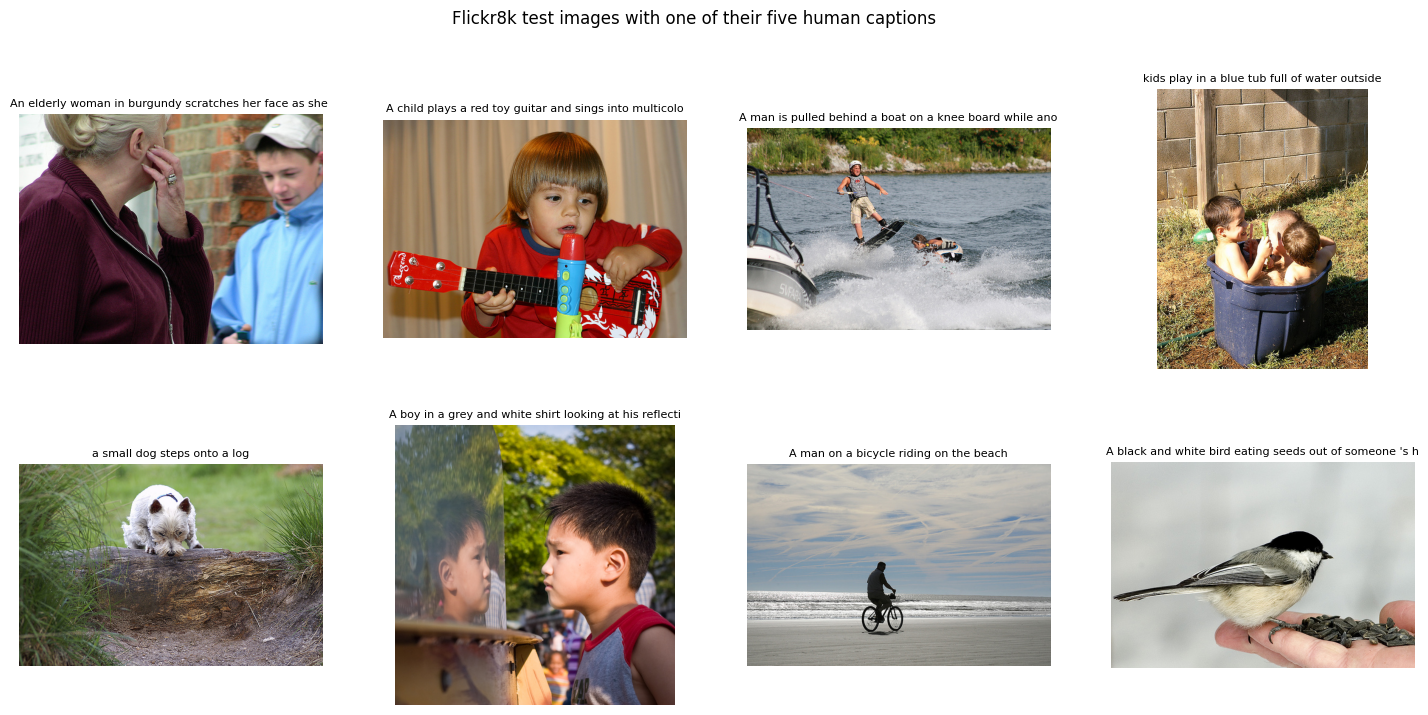

saved -> /content/week5_outputs/day1/day1_flickr_samples.png


In [5]:
FLICKR_ROOT = kaggle_dataset("adityajn105/flickr8k", "flickr8k")
IMAGE_DIR, CAPTIONS = load_flickr8k(FLICKR_ROOT)
TEST_NAMES, TRAIN_NAMES = flickr_split(CAPTIONS)
print(f"{len(CAPTIONS)} images, {sum(map(len, CAPTIONS.values()))} captions | test={len(TEST_NAMES)} train={len(TRAIN_NAMES)}")


def load_img(name: str) -> Image.Image:
    return Image.open(IMAGE_DIR / name).convert("RGB")


SAMPLE = TEST_NAMES[:8]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, name in zip(axes.flat, SAMPLE):
    ax.imshow(load_img(name))
    ax.set_title(CAPTIONS[name][0][:55], fontsize=8)
    ax.axis("off")
fig.suptitle("Flickr8k test images with one of their five human captions")
save_fig(fig, "day1_flickr_samples.png")

## 4 · From pixels to tokens (processor only, no model yet)

The processor does two things: it **resizes and patchifies** the image (Qwen3-VL: 16×16 patches, then 2×2 neighbouring patches are merged, so one visual token ≈ 32×32 pixels), and it **expands** each image placeholder in the chat template into that many `<|image_pad|>` tokens. The LLM's context therefore pays for every pixel.

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

Chat template (before expansion):
<|im_start|>user
<|vision_start|><|image_pad|><|vision_end|>Describe this image.<|im_end|>
<|im_start|>assistant

 width  height  pixels  visual_tokens patch_grid_thw  pixels_per_token
   224     170   38080             70    [1, 14, 20]        544.000000
   336     255   85680             80    [1, 16, 20]       1071.000000
   448     340  152320            154    [1, 22, 28]        989.090909
   672     509  342048            336    [1, 32, 42]       1018.000000
   896     679  608384            588    [1, 42, 56]       1034.666667
  1120     849  950880            945    [1, 54, 70]       1006.222222
  1344    1019 1369536           1344    [1, 64, 84]       1019.000000
  1792    1358 2433536           2352   [1, 84, 112]       1034.666667


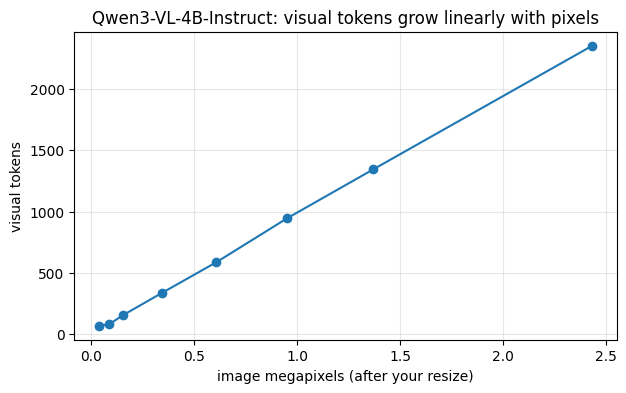

saved -> /content/week5_outputs/day1/day1_tokens_vs_resolution.png


In [6]:
proc = AutoProcessor.from_pretrained(VLM_ID)
demo = load_img(SAMPLE[0])
msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": "Describe this image."}]}]
print("Chat template (before expansion):\n" + proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True))

image_token = proc.image_token
image_token_id = proc.tokenizer.convert_tokens_to_ids(image_token)
rows = []
for side in [224, 336, 448, 672, 896, 1120, 1344, 1792]:
    img = demo.resize((side, round(side * demo.height / demo.width)))
    conv = [{"role": "user", "content": [{"type": "image", "image": img}, {"type": "text", "text": "Describe this image."}]}]
    enc = proc.apply_chat_template(conv, tokenize=True, add_generation_prompt=True, return_dict=True, return_tensors="pt")
    n_vis = int((enc["input_ids"][0] == image_token_id).sum())
    grid = enc["image_grid_thw"][0].tolist() if "image_grid_thw" in enc else None
    rows.append({"width": img.width, "height": img.height, "pixels": img.width * img.height, "visual_tokens": n_vis,
                 "patch_grid_thw": grid, "pixels_per_token": img.width * img.height / max(1, n_vis)})
TOKENS_VS_RES = pd.DataFrame(rows)
print(TOKENS_VS_RES.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(TOKENS_VS_RES.pixels / 1e6, TOKENS_VS_RES.visual_tokens, "o-")
ax.set_xlabel("image megapixels (after your resize)")
ax.set_ylabel("visual tokens")
ax.set_title(f"{VLM_ID.split('/')[-1]}: visual tokens grow linearly with pixels")
ax.grid(alpha=0.3)
save_fig(fig, "day1_tokens_vs_resolution.png")

Two things to notice: tokens ≈ pixels / (32×32) and the processor **snaps** sizes to a multiple of 32 (and enforces a minimum pixel budget, so tiny images get upscaled). A 1-megapixel invoice is ~1,000 tokens before you have asked a question.

## 5 · Load Qwen3-VL and look inside

In [7]:
QWEN = VLM(VLM_ID, max_side=MAX_SIDE)
print(type(QWEN.model).__name__, "| dtype:", QWEN.model.dtype, "| device:", QWEN.model.device)
if DEVICE == "cuda":
    print(f"GPU memory after load: {torch.cuda.memory_allocated() / 1e9:.1f} GB")


def component_of(name: str) -> str:
    n = name.lower()
    if any(k in n for k in ("merger", "projector")):
        return "projector"
    if any(k in n for k in ("visual", "vision_tower", "vision_model", "image_newline")):
        return "vision encoder"
    return "language model"


def param_breakdown(model) -> pd.Series:
    counts = Counter()
    for name, p in model.named_parameters():
        counts[component_of(name)] += p.numel()
    return pd.Series(counts).reindex(["vision encoder", "projector", "language model"]).fillna(0) / 1e6


def describe_config(model) -> dict:
    cfg = model.config
    vc, tc = getattr(cfg, "vision_config", None), getattr(cfg, "text_config", cfg)
    return {"vision_hidden": getattr(vc, "hidden_size", None), "vision_layers": getattr(vc, "depth", getattr(vc, "num_hidden_layers", None)),
            "patch_size": getattr(vc, "patch_size", None), "llm_hidden": getattr(tc, "hidden_size", None),
            "llm_layers": getattr(tc, "num_hidden_layers", None), "vocab": getattr(tc, "vocab_size", None)}


QWEN_PARAMS = param_breakdown(QWEN.model)
print("Parameters (millions):\n", QWEN_PARAMS.round(1).to_string())
print("Config:", describe_config(QWEN.model))
print("\nTop-level modules:")
for name, mod in QWEN.model.named_children():
    print(f"  {name}: {type(mod).__name__}")
    for sub, m in mod.named_children():
        print(f"    {name}.{sub}: {type(m).__name__}")

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

Qwen3VLForConditionalGeneration | dtype: torch.float16 | device: cuda:0
GPU memory after load: 8.9 GB
Parameters (millions):
 vision encoder     306.2
projector          109.1
language model    4022.5
Config: {'vision_hidden': 1024, 'vision_layers': 24, 'patch_size': 16, 'llm_hidden': 2560, 'llm_layers': 36, 'vocab': 151936}

Top-level modules:
  model: Qwen3VLModel
    model.visual: Qwen3VLVisionModel
    model.language_model: Qwen3VLTextModel
  lm_head: Linear


### The projector, caught in the act

A forward hook on the projector shows its output: one row per visual token, each row as wide as the LLM's hidden size. Those rows are spliced into the sequence where the `<|image_pad|>` tokens were.

In [8]:
def find_projector(model):
    for name, mod in model.named_modules():
        if name.endswith("merger") or name.endswith("multi_modal_projector"):
            return name, mod
    return None, None


captured = {}


def hook(_mod, _inp, out):
    t = out[0] if isinstance(out, (tuple, list)) else out
    captured["shape"] = tuple(t.shape)


proj_name, proj = find_projector(QWEN.model)
if proj is not None:
    handle = proj.register_forward_hook(hook)
    answer = QWEN.ask(demo, "Describe this image in one sentence.", max_new_tokens=40)
    handle.remove()
    print(f"projector module: {proj_name} -> output {captured.get('shape')}")
    print(f"visual tokens in the prompt: {QWEN.last['visual_tokens']} | LLM hidden: {describe_config(QWEN.model)['llm_hidden']}")
    print("answer:", answer)

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


projector module: model.visual.merger -> output (192, 2560)
visual tokens in the prompt: 192 | LLM hidden: 2560
answer: A woman in a maroon jacket wipes her eye while a young man in a blue jacket and cap looks on, standing against a brick wall.


## 6 · First runs: five things a VLM can do

All with greedy decoding (`do_sample=False`) so runs are reproducible.

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


      task                                                                prompt                                                                                                                                                                                                                                                                                                                                                               answer  visual_tokens  latency_s  tok_per_s
   caption                                  Describe this image in one sentence.                                                                                                                                                                                                                     A young child with brown hair, wearing a red shirt, is holding a red toy ukulele and a colorful toy microphone, appearing to sing or play along.            176       1.99       17.1
       vqa       What is the main person or animal

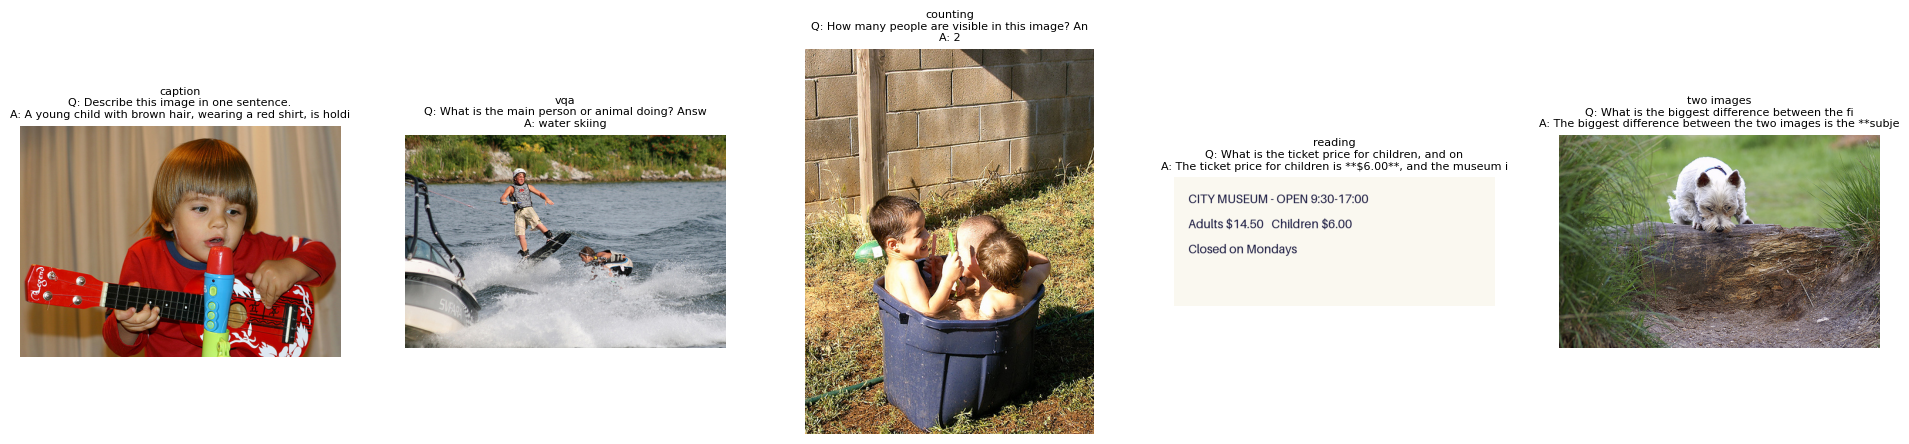

saved -> /content/week5_outputs/day1/day1_first_runs.png
[caption] human captions: ['A child plays a red toy guitar and sings into multicolored plastic microphone', 'A little boy is playing with a toy guitar and microphone']
[vqa] human captions: ['A man is pulled behind a boat on a knee board while another doing the same begins to fall', 'Two boys wakeboard']
[counting] human captions: ['kids play in a blue tub full of water outside', 'On a hot day , three small kids sit in a big container filled with water']


In [9]:
def text_card(lines: list[str], size=(900, 360)) -> Image.Image:
    """A synthetic sign with printed text, to test reading (OCR) ability."""
    img = Image.new("RGB", size, (250, 248, 240))
    d = ImageDraw.Draw(img)
    try:
        font = ImageFont.truetype("DejaVuSans-Bold.ttf", 34)
    except OSError:
        font = ImageFont.load_default(size=34)
    for i, line in enumerate(lines):
        d.text((40, 40 + i * 70), line, fill=(20, 20, 60), font=font)
    return img


SIGN = text_card(["CITY MUSEUM - OPEN 9:30-17:00", "Adults $14.50   Children $6.00", "Closed on Mondays"])
TASKS = [
    ("caption", [load_img(SAMPLE[1])], "Describe this image in one sentence."),
    ("vqa", [load_img(SAMPLE[2])], "What is the main person or animal doing? Answer in a few words."),
    ("counting", [load_img(SAMPLE[3])], "How many people are visible in this image? Answer with a number."),
    ("reading", [SIGN], "What is the ticket price for children, and on which day is it closed?"),
    ("two images", [load_img(SAMPLE[4]), load_img(SAMPLE[5])], "What is the biggest difference between the first and second image?"),
]
run_rows = []
for task, imgs, prompt in TASKS:
    ans = QWEN.ask(imgs, prompt, max_new_tokens=80)
    m = QWEN.last
    run_rows.append({"task": task, "prompt": prompt, "answer": ans, "visual_tokens": m["visual_tokens"],
                     "latency_s": round(m["latency_s"], 2), "tok_per_s": round(m["output_tokens"] / m["latency_s"], 1)})
RUNS = pd.DataFrame(run_rows)
pd.set_option("display.max_colwidth", 120)
print(RUNS.to_string(index=False))

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for ax, (task, imgs, prompt), row in zip(axes, TASKS, run_rows):
    ax.imshow(imgs[0])
    ax.set_title(f"{task}\nQ: {prompt[:45]}\nA: {row['answer'][:60]}", fontsize=8)
    ax.axis("off")
save_fig(fig, "day1_first_runs.png")
for task, name in [("caption", SAMPLE[1]), ("vqa", SAMPLE[2]), ("counting", SAMPLE[3])]:
    print(f"[{task}] human captions: {CAPTIONS[name][:2]}")

## 7 · The cost of pixels: visual tokens vs latency

Same image, same question, different resolution. Prefill (reading the prompt) scales with prompt length; decoding cost per output token also rises with context length.

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


 max_side  visual_tokens  input_tokens  latency_s
      256             70            87      1.603
      448            140           157      1.838
      672            176           193      1.769
      896            176           193      1.794
     1344            176           193      1.869


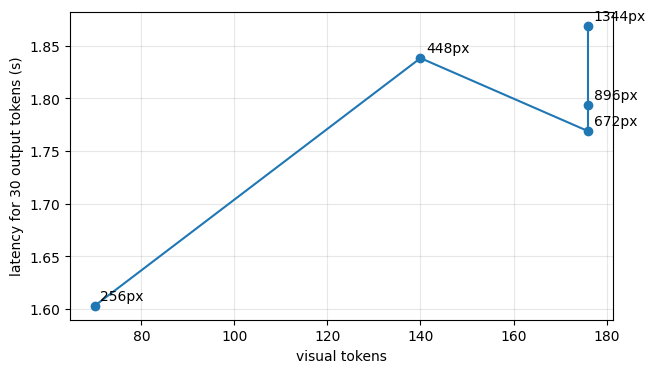

saved -> /content/week5_outputs/day1/day1_latency_vs_tokens.png


In [10]:
lat_rows = []
img = load_img(SAMPLE[1])
for side in [256, 448, 672, 896, 1344]:
    QWEN.ask(img, "Describe this image in one sentence.", max_new_tokens=30, max_side=side)
    lat_rows.append({"max_side": side, **{k: QWEN.last[k] for k in ("visual_tokens", "input_tokens", "latency_s")}})
LATENCY = pd.DataFrame(lat_rows)
print(LATENCY.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(LATENCY.visual_tokens, LATENCY.latency_s, "o-")
for _, r in LATENCY.iterrows():
    ax.annotate(f"{int(r.max_side)}px", (r.visual_tokens, r.latency_s), textcoords="offset points", xytext=(4, 4))
ax.set_xlabel("visual tokens")
ax.set_ylabel("latency for 30 output tokens (s)")
ax.grid(alpha=0.3)
save_fig(fig, "day1_latency_vs_tokens.png")

## 8 · A LLaVA-style model for comparison

LLaVA = CLIP/SigLIP vision encoder → **2-layer MLP projector** → LLM, trained in two stages: (1) align the projector on image-caption pairs with everything else frozen, (2) **visual instruction tuning** on GPT-generated image conversations. LLaVA-OneVision adds "AnyRes" tiling for high-resolution images. Qwen3-VL keeps the same three-part recipe but trains its own ViT with native dynamic resolution and merges 2×2 patches in the projector.

processor_config.json:   0%|          | 0.00/178 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/826 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/1.73k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.59k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.79GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/716 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/126 [00:00<?, ?B/s]

LLaVA config: {'vision_hidden': 1152, 'vision_layers': 26, 'patch_size': 14, 'llm_hidden': 896, 'llm_layers': 24, 'vocab': 152000}
  model: LlavaOnevisionModel ['vision_tower: SiglipVisionModel', 'multi_modal_projector: LlavaOnevisionMultiModalProjector', 'language_model: Qwen2Model']
  lm_head: Linear []
Parameters (millions):
                 Qwen3-VL  LLaVA-OV-0.5B
vision encoder     306.2          397.7
projector          109.1            1.8
language model    4022.5          494.1


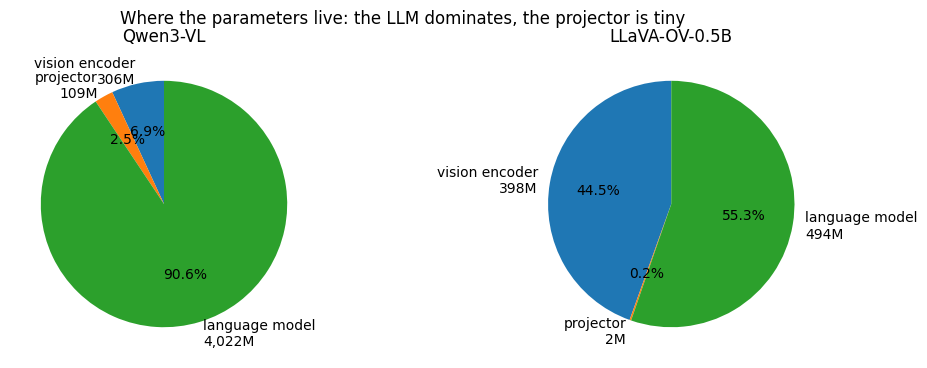

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


saved -> /content/week5_outputs/day1/day1_param_breakdown.png


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


    task                                                                                   qwen3_vl                                                                      llava_ov  llava_visual_tokens  llava_latency_s
 caption A young child with brown hair, wearing a red shirt, is holding a red toy ukulele and a col A young child is playing a red ukulele with a blue and yellow toy microphone.                 1782             1.18
     vqa                                                                               water skiing                                                                  Water skiing                 1836             0.58
counting                                                                                          2                                   There are two people visible in this image.                 1737             0.75
 reading       The ticket price for children is **$6.00**, and the museum is **closed on Mondays**.          The ticket price for childr

In [11]:
PARAMS = {"Qwen3-VL": QWEN_PARAMS}
LLAVA = None
if RUN_LLAVA:
    LLAVA = VLM(LLAVA_ID, max_side=MAX_SIDE)
    PARAMS["LLaVA-OV-0.5B"] = param_breakdown(LLAVA.model)
    print("LLaVA config:", describe_config(LLAVA.model))
    for name, mod in LLAVA.model.named_children():
        print(f"  {name}: {type(mod).__name__}", [f"{s}: {type(m).__name__}" for s, m in mod.named_children()][:4])
PARAMS_DF = pd.DataFrame(PARAMS).round(1)
print("Parameters (millions):\n", PARAMS_DF.to_string())

fig, axes = plt.subplots(1, len(PARAMS), figsize=(6 * len(PARAMS), 4))
for ax, (model_name, s) in zip(np.atleast_1d(axes), PARAMS.items()):
    ax.pie(s.values, labels=[f"{k}\n{v:,.0f}M" for k, v in s.items()], autopct="%1.1f%%", startangle=90)
    ax.set_title(model_name)
fig.suptitle("Where the parameters live: the LLM dominates, the projector is tiny")
save_fig(fig, "day1_param_breakdown.png")

if LLAVA is not None:
    cmp_rows = []
    for task, imgs, prompt in TASKS[:4]:
        ans = LLAVA.ask(imgs, prompt, max_new_tokens=80)
        cmp_rows.append({"task": task, "qwen3_vl": RUNS.loc[RUNS.task == task, "answer"].item()[:90], "llava_ov": ans[:90],
                         "llava_visual_tokens": LLAVA.last["visual_tokens"], "llava_latency_s": round(LLAVA.last["latency_s"], 2)})
    print(pd.DataFrame(cmp_rows).to_string(index=False))

## 9 · Hallucination probe (POPE-style)

[POPE](https://arxiv.org/abs/2305.10355) asks "Is there a X in the image?" for objects that are present and objects that are not. A model that says "yes" too often is **hallucinating objects** — the failure that later shows up as invented invoice numbers. Labels come from the five human captions (an object counts as present if any caption mentions it and absent if none does; captions can miss things, so a few "absent" labels are wrong).

In [12]:
OBJECTS = {
    "dog": ["dog", "dogs", "puppy"], "person": ["man", "woman", "boy", "girl", "child", "person", "people", "men", "women", "kid", "kids", "children"],
    "ball": ["ball"], "water": ["water", "lake", "river", "ocean", "pool", "sea"], "bicycle": ["bike", "bicycle", "biker", "cyclist"],
    "car": ["car", "cars"], "grass": ["grass", "grassy"], "snow": ["snow", "snowy"], "horse": ["horse", "horses"], "cat": ["cat"],
    "boat": ["boat", "boats"], "building": ["building", "buildings"], "bench": ["bench"], "hat": ["hat", "helmet"], "sand": ["sand", "beach"],
}


def mentioned(obj: str, caps: list[str]) -> bool:
    words = set(re.findall(r"[a-z]+", " ".join(caps).lower()))
    return any(w in words for w in OBJECTS[obj])


rng = random.Random(SEED)
probes = []
for name in TEST_NAMES[100:]:
    pos = [o for o in OBJECTS if mentioned(o, CAPTIONS[name])]
    neg = [o for o in OBJECTS if not mentioned(o, CAPTIONS[name])]
    if pos and neg:
        probes += [(name, rng.choice(pos), True), (name, rng.choice(neg), False)]
    if len(probes) >= 2 * N_POPE:
        break


def yes_no(ans: str) -> bool | None:
    a = ans.strip().lower()
    return True if a.startswith("yes") else False if a.startswith("no") else None


def pope(vlm: VLM) -> dict:
    preds = []
    for name, obj, truth in probes:
        a = vlm.ask(load_img(name), f"Is there a {obj} in this image? Answer yes or no.", max_new_tokens=3)
        preds.append((yes_no(a), truth))
    tp = sum(p is True and t for p, t in preds)
    fp = sum(p is True and not t for p, t in preds)
    fn = sum(p is not True and t for p, t in preds)
    return {"accuracy": np.mean([p == t for p, t in preds]), "precision": tp / max(1, tp + fp), "recall": tp / max(1, tp + fn),
            "yes_ratio": np.mean([p is True for p, _ in preds]), "unparsed": sum(p is None for p, _ in preds), "n": len(preds)}


POPE = {"Qwen3-VL": pope(QWEN)}
if LLAVA is not None:
    POPE["LLaVA-OV-0.5B"] = pope(LLAVA)
POPE_DF = pd.DataFrame(POPE).T.round(3)
print(POPE_DF.to_string())
print("A balanced probe has yes_ratio 0.5; a ratio well above 0.5 with lower precision means the model invents objects.")

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

               accuracy  precision  recall  yes_ratio  unparsed     n
Qwen3-VL           0.95      0.929   0.975      0.525       0.0  80.0
LLaVA-OV-0.5B      0.95      0.909   1.000      0.550       0.0  80.0
A balanced probe has yes_ratio 0.5; a ratio well above 0.5 with lower precision means the model invents objects.


## 10 · Visual instruction tuning: what the training data looks like

LLaVA's stage-2 data is a conversation about an image. The training loss is computed **only on the assistant's tokens**: the image tokens and the user's question are context (label `-100`), the answer is what the model learns to produce. Below we build one such sample from a Flickr8k caption and show which tokens would be supervised.

In [13]:
name = SAMPLE[1]
sample = [
    {"role": "user", "content": [{"type": "image", "image": fit_image(load_img(name), 448)}, {"type": "text", "text": "What is happening in this picture?"}]},
    {"role": "assistant", "content": [{"type": "text", "text": CAPTIONS[name][0] + "."}]},
]
print(json.dumps([{"role": m["role"], "content": [c.get("text", "<image>") for c in m["content"]]} for m in sample], indent=1))
enc = QWEN.processor.apply_chat_template(sample, tokenize=True, return_dict=True, return_tensors="pt")
ids = enc["input_ids"][0]
assistant_start = QWEN.processor.tokenizer.encode("<|im_start|>assistant\n", add_special_tokens=False)
starts = [i for i in range(len(ids) - len(assistant_start) + 1) if ids[i:i + len(assistant_start)].tolist() == assistant_start]
labels = torch.full_like(ids, -100)
if starts:
    s = starts[-1] + len(assistant_start)
    labels[s:] = ids[s:]
n_img = int((ids == QWEN.processor.tokenizer.convert_tokens_to_ids(QWEN.processor.image_token)).sum())
n_sup = int((labels != -100).sum())
print(f"sequence length {len(ids)} | image tokens {n_img} | supervised (assistant) tokens {n_sup} ({n_sup / len(ids):.1%})")
print("supervised text:", repr(QWEN.processor.tokenizer.decode(ids[labels != -100])))

[
 {
  "role": "user",
  "content": [
   "<image>",
   "What is happening in this picture?"
  ]
 },
 {
  "role": "assistant",
  "content": [
   "A child plays a red toy guitar and sings into multicolored plastic microphone."
  ]
 }
]
sequence length 175 | image tokens 140 | supervised (assistant) tokens 18 (10.3%)
supervised text: 'A child plays a red toy guitar and sings into multicolored plastic microphone.<|im_end|>\n'


## 11 · Save a summary

In [14]:
summary = {
    "model": VLM_ID, "dtype": str(QWEN.model.dtype), "max_side": MAX_SIDE,
    "params_millions": PARAMS_DF.to_dict(), "tokens_vs_resolution": TOKENS_VS_RES.drop(columns="patch_grid_thw").to_dict("records"),
    "latency_vs_tokens": LATENCY.to_dict("records"), "first_runs": RUNS.to_dict("records"), "pope": POPE_DF.to_dict("index"),
}
(OUTPUT_DIR / "day1_summary.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
print("saved ->", OUTPUT_DIR / "day1_summary.json")

saved -> /content/week5_outputs/day1/day1_summary.json


## Checklist

- [ ] I can draw the three blocks of a VLM and say which one holds most of the parameters.
- [ ] I can estimate how many visual tokens an image of a given size costs, and why tiny text needs more pixels.
- [ ] I saw the projector output shape match (visual tokens × LLM hidden size).
- [ ] I know where the loss is applied in visual instruction tuning.
- [ ] I measured the yes-bias of two models on the POPE-style probe.

**Next (Day 2):** Visual Question Answering on receipts and the Week 4 invoices — head-to-head with OCR.